## Assignment 2

In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [51]:
from google.colab import files
uploaded = files.upload()

Saving SLCM_rent_arrears_student_clean.csv to SLCM_rent_arrears_student_clean (2).csv


## Part 1 – Get to Know the Prediction Problem

>

> Add blockquote





##### 1. Load the dataset and examine its structure.

In [26]:
#Load the CSV file into pandas.
df = pd.read_csv("SLCM_rent_arrears_student_clean.csv")
#Display the first 5 rows
df.head()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [27]:
#Report the number of rows and columns
df.shape

(1754, 14)

In [8]:
#Print the column names.
df.columns

Index(['record_id', 'adults_in_household', 'children_in_household',
       'household_has_65plus', 'monthly_household_income', 'income_sources',
       'employment_status', 'has_housing_voucher', 'eviction_in_progress',
       'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter',
       'monthly_rent', 'past_due_rent'],
      dtype='object')

In [9]:
#Use info() to inspect the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   object 
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null   object 
 4   monthly_household_income    1646 non-null   float64
 5   income_sources              1754 non-null   object 
 6   employment_status           1754 non-null   object 
 7   has_housing_voucher         1754 non-null   object 
 8   eviction_in_progress        1753 non-null   object 
 9   behind_on_utilities         1747 non-null   object 
 10  main_reason_behind_on_rent  1738 non-null   object 
 11  intake_quarter              1754 non-null   object 
 12  monthly_rent                1746 non-null   float64
 13  past_due_rent               1754 

####Answers:
###### **Which variable will be the target?**

The target variable is past_due_rent

##### **Which columns appear to be numerical?**

Numerical columns are adults_in_household, children_in_household, monthly_household_income, monthly_rent.

#### **Which columns appear to be categorical?**

Categorical columns are household_has_65plus, income_sources, employment_status, has_housing_voucher, eviction_in_progress, behind_on_utilities, main_reason_behind_on_rent, intake_quarter. Records_id is an identifier



##### 2. Investigate missing values.

In [10]:
#Calculate the number of missing values in every column
df.isna().sum()

,0
record_id,0
adults_in_household,0
children_in_household,0
household_has_65plus,0
monthly_household_income,108
income_sources,0
employment_status,0
has_housing_voucher,0
eviction_in_progress,1
behind_on_utilities,7


In [11]:
#Identify which variables contain missing data.
df.isna().any()


,0
record_id,False
adults_in_household,False
children_in_household,False
household_has_65plus,False
monthly_household_income,True
income_sources,False
employment_status,False
has_housing_voucher,False
eviction_in_progress,True
behind_on_utilities,True


##### **Missing Values**
I am not removing the missing values since removing them would throw away about 140 rows of data. I’ll instead impute the median for the numerical columns and the most frequent value for categorical columns using their respective preprocessing pipeline.

In [12]:
df_clean=df.copy()

##### 3. Explore the target variable: past_due_rent

In [13]:
#Use describe: count,mean,median, standard deviation, minimum, maximum
df_clean['past_due_rent'].describe()

,past_due_rent
count,1754.000000
mean,2408.006933
std,2089.515372
min,0.000000
25%,1050.000000
50%,2000.000000
75%,3200.000000
max,20000.000000


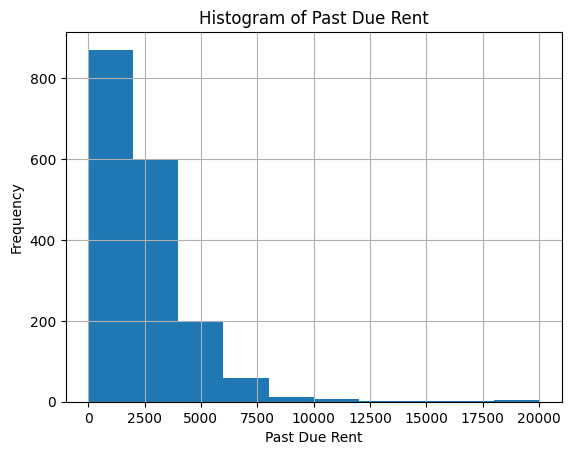

In [14]:
#histogram
df_clean['past_due_rent'].hist()
plt.xlabel('Past Due Rent')
plt.ylabel('Frequency')
plt.title('Histogram of Past Due Rent')
plt.show()



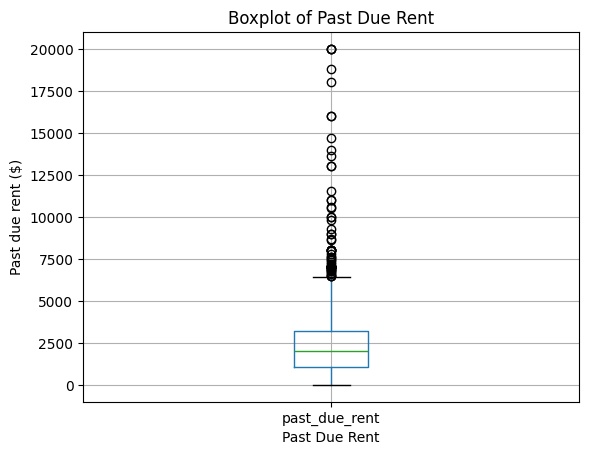

In [64]:
#boxplot
df_clean.boxplot(column=['past_due_rent'])
plt.xlabel('Past Due Rent')
plt.ylabel('Past due rent ($)')
plt.title('Boxplot of Past Due Rent')
plt.show()

##### Answer:
##### **What does the distribution look like?**

Strong right skew distribution since the histogram is compacted on the left. This is also displayed since the box sits low on the boxplot and many outliers are present above the upper whisker.

##### **Is the distribution symmetric or skewed?**
It is not symmetric. It is skewed as mentioned above.

##### **Are the mean and median similar?**

The mean, 2,408, is higher than the median, 2000. This is also relates back to the right-skewed distribution since a small number of very large values increases the mean where as the median remains low.

##### **Do you notice any unusually high values?**

Yes, on the boxplot there are multiple values we would consider outliers since they reside above the 75 percentile whisker.

##### **Why might rent-arrears data naturally contain a wide range of values?**
Rent-arrears data naturally contains a wide range bacause different households fall behind for different lengths of time. Therefore someone who is one month behind will owe less than someone who is six months behind. This can cause a natural spread between the data.


##### **Removing Outliers**

I decided not to remove any high values, outliers, since they are real households and removing them would make my models less reliable to the data I am trying to predict


#### 4. Create your input features and target.

In [35]:
#Create X and y using past_due_rent as the target. Do not use record_id as an input feature.
X = df_clean.drop(columns=['record_id', 'past_due_rent'])
y = df_clean['past_due_rent']

##### Answer:
##### Why should record_id not be used to predict past-due rent?
Record_id should not be used to predict past_due rent because it is a label that helps identify each row. Therefore it has no impact on the household itself. If it were included the model could treat it as something that influences our variable and ultimately impact our models accuracy

##### 5. Separate the numerical and categorical features

In [36]:
#Create lists containing numerical features and categorical features.Display both lists
numerical_features = ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
categorical_features = ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']
print(numerical_features)
print(categorical_features)

['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


##### **Explain why machine-learning models require different preparation steps for numerical and categorical variables**
Numerical and categorical variables need different preparation because they contain different info. Numerical variale hold numbers, so the model can use them directly. Where as categorical variable contain text and regression models can only compute using numbers. Therefore they need to be converted into numerical form using encoding so the model can compute there importance.

##### 6.Split the data into training and testing sets

In [61]:
#Split data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [59]:
#Report the dimensions of X_train, X_test, y_train, and y_test.using test size=0.2 and random_state=42
print("X train: ",X_train.shape)
print("X test: ",X_test.shape)
print("Y train: ",y_train.shape)
print("Y test: ",y_test.shape)

X train:  (1403, 12)
X test:  (351, 12)
Y train:  (1403,)
Y test:  (351,)


##### **Why should the model be evaluated using data that was not used during training?**

A model will score very well on data it has already learned by simply memorizing it.Therefore a training score doesn't accurately show how well it really works. Testing on data it hasn't seen will truly show how well it will predict new households.


##### 7. Prepare the numerical variables

In [20]:
#create a numerical preprocessing pipeline
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

##### **How did you handle missing numerical values?**

I handled missing numerical values by filling them with the median of the training data. I chose the median because income and rent are skewed, and the median isn’t pulled by extreme values the way the mean is.

##### **Why might feature scaling matter when comparing Linear, Ridge, and Lasso models?**

Scaling matters when comparing Linear, Ridge, and Lasso because Ridge and Lasso penalize the size of the coefficients. If features are on different scales the penalty hits them unevenly. Scaling makes every feature so the penalty is fair.

##### 8. Prepare the categorical variables.

In [21]:
#create categorical preprocessng pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

##### Answer:
##### **Why can the regression models not directly use values such as employment categories?**

Regression models can't use values like employment categories since they are numerical texts. Regression models need numnbers to be multiple to compute. Therefore values like "Employed" or "Unemployed" cannot be used until they are turned into numbers

##### **Why is one-hot encoding appropriate for these variables?**

One-hot encoding is appropriate becausenit gives each category its own 0/1 column. Therefore the model can learn each values effect without assuming any order.

#####**Why would assigning arbitrary numbers such as 1, 2, 3, and 4 to unordered categories potentially be misleading?**
Using 1,2,3,4 would be misleading because it makes the categories seemed ranked. Therefore the model would treate the 4's as more than the 2's even though they are actually valued equally

##### 9. Combine your preprocessing steps.

In [22]:
# Use column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

##### **Explain briefly why using a preprocessing pipeline is useful.**
A preprocessing pipeline is useful because it uses the same steps as the train/test data and it learns from the training data as well. It also resuses the same preproessing for all the models used therefore they'll all be computed similarily

###Part 3 – Build and Compare Regression Models

##### 10. Build a Multiple Linear Regression model

In [23]:
#Create pipeline containing preprocessing and Linear model
Linear_model=Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

In [24]:
#Calculate RMSE and R^2
Linear_model.fit(X_train, y_train)
y_pred = Linear_model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("RMSE:", rmse)
print("R^2:", r2)

RMSE: 1861.2128270263634
R^2: 0.15490567480599293


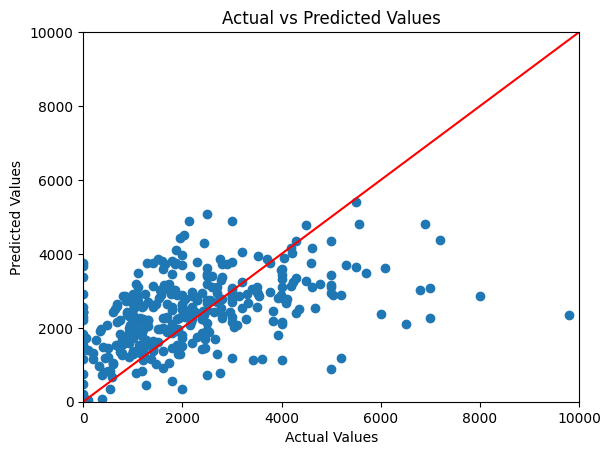

In [25]:
#Actual vs predicted values scatter plot, linear line
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red')

plt.xlim(0, 10000)
plt.ylim(0, 10000)
plt.show()

##### Answer:
##### **What does RMSE represent in this problem?**
RMSE is the typical size of the model's mistakes in dolalrs. The RMSE of 1861 means the predictions are usually off by 1861 dollars.

##### **What does the R² score tell you?**
An R^2 of 0.1555 means the model explains 15% of why past due rent differs between households. Therefore most of the variance is explained by external values

##### **Based on the graph, how closely do the predictions match the actual values?**


The predictions don't match the actual values closely. The points are scattered far from the diagnol line.

#####**Do you notice cases where the model makes large prediction errors?**
Yes, the largest prediction errors occur towards the extreme values, specificlly with those who have a high past-due rent

##### 11. Build a Polynomial Regression model.

In [29]:
# numerical pipeline
num_poly = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler())
])
# combine: polynomial on numerical columns, normal one-hot on categorical columns
poly_preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_poly, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [30]:
#create polynomial model
poly_model = Pipeline([
    ('preprocessor', poly_preprocessor),
    ('model', LinearRegression())
])

In [31]:
#train model
poly_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('poly',
                                                                   PolynomialFeatures(include_bias=False)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['adults_in_household',
                                                   'children_in_household',
                                                   'monthly_household_income',
                                                   'monthly_rent']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['household_has_65plus',
                                                   'income_sources',
                                                   'employment_status',
                                                   'has_housing_voucher',
                                                   'eviction_in_progress',
                                                   'behind_on_utilities',
                                                   'main_reason_behind_on_rent',
                                                   'intake_quarter'])])),
                ('model', LinearRegression())])

In [32]:
#predict model
y_pred = poly_model.predict(X_test)

In [33]:
#Calculate and output RMSE and R^2
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("RMSE:", rmse)
print("R^2:", r2)


RMSE: 1875.0363526767132
R^2: 0.14230575540605894


 ##### Answers:

 ##### **Did Polynomial Regression perform better or worse than Linear Regression?**
Slightly worse. The RMSE increased, ~1875 dollars, and the R^2 decreased, 0.142. Therefore the models errors increased and it explains less of our target variable's variance compared to the Linear Regression

#####**What does a degree-2 polynomial allow the model to represent that Linear Regression cannot?**
It can capture the curved relationships between features where as a linear model can only fit straight line relationships

#####**Why could using a very high polynomial degree lead to overfitting?**
The model is more flexible and therefore will incorporate quirks in the training data that ultmately makes its performance worse on new data.

#####**Did making the model more complicated automatically make it better?**
No. The complexity made the results worse instead of better.

##### 12. Build a Ridge Regression model.

In [37]:
#alpha=1. Calculate RMSE and R^2
ridge_model1 = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0))
])
ridge_model1.fit(X_train, y_train)
y_pred = ridge_model1.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R^2:", r2)



RMSE: 1849.1758934275128
R^2: 0.1658012054724709


In [38]:
#alpha=10
ridge_model2 = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=10.0))
])
ridge_model2.fit(X_train, y_train)
y_pred = ridge_model2.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("RMSE:", rmse)
print("R^2:", r2)


RMSE: 1840.5659623387016
R^2: 0.17355133159152514


In [39]:
#alpha=100
ridge_model3 = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=100.0))
])
ridge_model3.fit(X_train, y_train)
y_pred = ridge_model3.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)
print("RMSE:", rmse)
print("R^2:", r2)

RMSE: 1837.4051567959143
R^2: 0.17638741634076527


In [40]:
#alpha=1000
ridge_model4 = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1000.0))
])
ridge_model4.fit(X_train, y_train)
y_pred = ridge_model4.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("RMSE:", rmse)
print("R^2:", r2)

RMSE: 1873.434011968461
R^2: 0.1437710402567599


In [41]:
# Compare all alphas
ridge_models = {
    "Ridge alpha=1": ridge_model1,
    "Ridge alpha=10": ridge_model2,
    "Ridge alpha=100": ridge_model3,
    "Ridge alpha=1000": ridge_model4,
}

alpha_ridge_comparison = pd.DataFrame({
    "RMSE": {name: np.sqrt(mean_squared_error(y_test, m.predict(X_test))) for name, m in ridge_models.items()},
    "R²": {name: r2_score(y_test, m.predict(X_test)) for name, m in ridge_models.items()},
}).round(3)

alpha_ridge_comparison

,RMSE,R²
Ridge alpha=1,1849.176,0.166
Ridge alpha=10,1840.566,0.174
Ridge alpha=100,1837.405,0.176
Ridge alpha=1000,1873.434,0.144


In [42]:
# Best Ridge model = highest R²
best_ridge_name = alpha_ridge_comparison["R²"].idxmax()
ridge_model = ridge_models[best_ridge_name]
pred_ridge = ridge_model.predict(X_test)

print("Best Ridge:", best_ridge_name)
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_ridge)))
print("R^2:", r2_score(y_test, pred_ridge))

Best Ridge: Ridge alpha=100
RMSE: 1837.4051567959143
R^2: 0.17638741634076527


##### Answer:
#####**How does Ridge Regression compare with Linear Regression?**
Ridge did slightly better than Linear Regression. At is best, alpha=100, Ridge had an RMSE of ~1837 and an R^2 of 0.176, compared with about 1,861 and 0.155 for Linear.

#####**What does regularization do?**
It adds a penalty for large coefficients, which keeps the model from relying too heavily on any one feature or fitting noise in the training data.

#####Why can regularization be useful when a model contains many features?
 A model with many features can easily overfit, and regularization keeps it steadier so it does better on new data.

##### 13. Build a Lasso Regression model.

In [43]:
#alpha=1
lasso_model1 = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=1.0))
])
lasso_model1.fit(X_train, y_train)
y_pred = lasso_model1.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("RMSE:", rmse)
print("R^2:", r2)

RMSE: 1841.893223067021
R^2: 0.1723589718668952


In [44]:
#alpha=10
lasso_model2 = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=10.0))
])
lasso_model2.fit(X_train, y_train)
y_pred = lasso_model2.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("RMSE:",rmse)
print("R^2:",r2)

RMSE: 1826.4430264030984
R^2: 0.18618559930653933


In [45]:
#alpha=100
lasso_model3 = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=100.0))
])
lasso_model3.fit(X_train, y_train)
y_pred = lasso_model3.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("RMSE:",rmse)
print("R^2:",r2)

RMSE: 1865.1479303950282
R^2: 0.1513283847586574


In [46]:
# Compare all alphas
lasso_models = {
    "Lasso alpha=1": lasso_model1,
    "Lasso alpha=10": lasso_model2,
    "Lasso alpha=100": lasso_model3,
}

alpha_lasso_comparison = pd.DataFrame({
    "RMSE": {name: np.sqrt(mean_squared_error(y_test, m.predict(X_test))) for name, m in lasso_models.items()},
    "R²": {name: r2_score(y_test, m.predict(X_test)) for name, m in lasso_models.items()},
}).round(3)

alpha_lasso_comparison


,RMSE,R²
Lasso alpha=1,1841.893,0.172
Lasso alpha=10,1826.443,0.186
Lasso alpha=100,1865.148,0.151


In [47]:
# Best Lasso model = highest R²
best_lasso_name = alpha_lasso_comparison["R²"].idxmax()
lasso_model = lasso_models[best_lasso_name]
pred_lasso = lasso_model.predict(X_test)

print("Best Lasso:", best_lasso_name)
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_lasso)))
print("R^2:", r2_score(y_test, pred_lasso))

Best Lasso: Lasso alpha=10
RMSE: 1826.4430264030984
R^2: 0.18618559930653933


##### Answer:

##### **How does Lasso compare with Linear and Ridge Regression?**

Lasso did the best of three. At alpha=10 it had an RMSE of about 1,826 and an R^2 of about 0.186. Ridge had an RMSE of ~1837 and an R^2 of 0.176, and Linear had about 1,861 and 0.155.

##### **What is an important difference between Ridge and Lasso?**
Ridge shrinks coefficients toward zero but keeps every feature in the model, whereas Lasso can remove features completely.

##### **What can happen to some coefficients when Lasso is used?**
They become exactly zero, which means those features are dropped from the model

##### 14. Compare all four models.

In [48]:
#Create DataFrame containing all the test results of the 4 models
predictions = pd.DataFrame({
    "Linear Regression": Linear_model.predict(X_test),
    "Polynomial Regression": poly_model.predict(X_test),
    "Ridge Regression": ridge_model.predict(X_test),
    "Lasso Regression": lasso_model.predict(X_test)
})

#add in scores
rows = []
for model in predictions.columns:
    mse = mean_squared_error(y_test, predictions[model])
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions[model])
    rows.append({"Model": model, "RMSE": rmse, "R²": r2})

#Combine
comparison = pd.DataFrame(rows).round(3)
comparison

,Model,RMSE,R²
0,Linear Regression,1861.213,0.155
1,Polynomial Regression,1875.036,0.142
2,Ridge Regression,1837.405,0.176
3,Lasso Regression,1826.443,0.186


#####  Answer:
##### **Which model has the lowest RMSE?**
Lasso Regression has the lowest RMSE at ~1826.


##### **Which model has the highest R^2?**
Lasso Regression has the highest R^2 at roughly 0.186.

#####**Are the differences between the models large or small?**
The margin between the models is very small. 49 dollars of RMSE seperates the best model, Lasso, and the worst model, Polynomial. Also every R^2 falls between 0.142 and 0.186.

#####**Did the most complicated model perform the best?**
No. Polynomial Regression is considered the most complicated model and it did the worse in terms of RMSE and R^2.

#####**Which model would you continue investigating? Explain your choice using evidence from your results.**
I should continue to investigate Lasso Regression, since it has the lowest RMSE and highest R^2 of the four models.


##### 15. Test your selected model on two hypothetical households.

In [52]:
#Case 1:
case1 = pd.DataFrame([{
    "adults_in_household": 2,
    "children_in_household": 2,
    "household_has_65plus": "No",
    "monthly_household_income": 1800,
    "income_sources": "Part-time employment",
    "employment_status": "Employed, but need more hours and/or different work",
    "has_housing_voucher": "No",
    "eviction_in_progress": "Yes",
    "behind_on_utilities": "Yes",
    "main_reason_behind_on_rent": "Lost a job/had hours cut",
    "intake_quarter": "2026-Q3",
    "monthly_rent": 1500
}])

In [53]:
#Lasso Prediction Case 1
pred_case1 = lasso_model.predict(case1)
print(f"Case 1 predicted past-due rent: ${pred_case1[0]:,.0f}")

Case 1 predicted past-due rent: $3,225


In [54]:
# Case 2:
case2 = pd.DataFrame([{
    "adults_in_household": 1,
    "children_in_household": 0,
    "household_has_65plus": "Yes",
    "monthly_household_income": 1300,
    "income_sources": "Social Security - SSI/SSDI",
    "employment_status": "Other",
    "has_housing_voucher": "Yes",
    "eviction_in_progress": "I don't know",
    "behind_on_utilities": "No",
    "main_reason_behind_on_rent": "Unexpected expense",
    "intake_quarter": "2026-Q3",
    "monthly_rent": 650
}])

In [55]:
#Lasso Case 2
pred_case2 = lasso_model.predict(case2)
print(f"Case 2 predicted past-due rent: ${pred_case2[0]:,.0f}")

Case 2 predicted past-due rent: $657


##### **How are the two households different?**
Case 1 is a family of four, two adults and two children, with a 1800 monthly income from part time work, no housing voucher, an eviction in progress, utilitiy problems and 1500 due in rent. Where as Case 2 is a single older adult with a 1300 income, no utility problems and 650 behind on rent because of one unexpected expense.
##### **How different are the predictions?**
Case 1 is predicted to owe about 3,225 dollars in past-due rent, and Case 2 is predicted to owe about 657 dollars. The gap between the two is about 2,568 dollars, so the model predicts that Case 1 owes nearly five times as much as Case 2.

##### **Does the difference seem reasonable based on the information you provided?**
Yes. Case 1 has more risk factors, such as a larger household, double the rent, eviction issue and utilitity problems. These factors can cause an increase in the estimated past due rent amount therefore this large difference makes sense.

###Part 4 – Interpret the Results

###### 16. What did your models tell you?

(0.0, 10000.0)

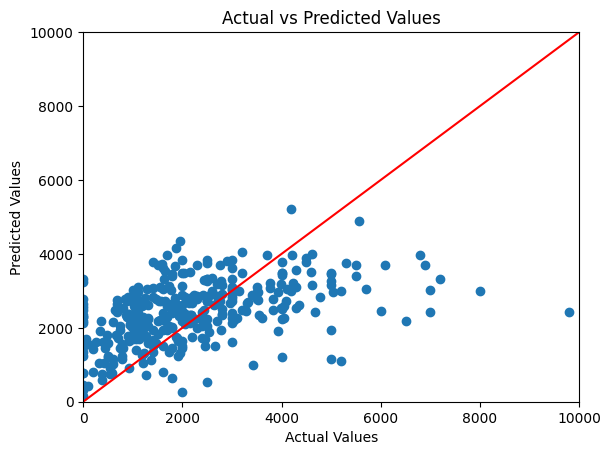

In [63]:
#Plot lasso model prediction actual vs expected
plt.scatter(y_test, pred_lasso)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red')

plt.xlim(0, 10000)
plt.ylim(0, 10000)

##### **Which model performed best on the test data?**

The Lasso Regression model performed the best on the test data. It had the lowest RMSE, ~1826, and the highest R^2, 0.186.

#####**Approximately how large are the model's typical prediction errors?**

RMSE is the typical prediction error, therefore the model's predictions are typically off by ~1826 dollars. The others models prediction errors were between 1837 and 1875.


#####**Did Polynomial Regression provide a meaningful improvement?**
No the Polynomial Regression ddi not provide any improvement. The RMSE of ~1875 dollars and R^2 of 0.142 were slightly worse than the original Linear Regression model and Lasso Regression.

#####**Did regularization improve the results?**

Regularization fractionally improved the model. Both the Lasso and Ridges R^2 were higher,0.186 and 0.176, than the Linear and Polynomial models, 0.155 and 0.142. On top of that there RMSE's, ~1826 and ~1837, were lower than the Linear and Polynomial models, ~1861 an ~1875. Ridge and Lasso use regularization. Lasso penalizes and removes the large coefficients. Where as Ridge shrinks the large coefficients. This ultimately made their models better than Linear and Polynomial.


#####**What does your model appear able to predict reasonably well?**

The Lasso Actual vs. Predicted plot suggests the model predicts reasonably well for households with moderate past-due rent, roughly 1,000 to 4,000 dollars. In that range, many points fall close to the red prediction line. This makes sense since it is  where most households in the data fall, the median is $2,000, therefore the model has the most information to learn from there. The fit is only moderate, though: the points are still scattered widely around the line, which matches the low R^2 of 0.186.


#####**Where does it appear to struggle?**
The model appears to struggle with households that have very high past due rent. In the Lasso Actual vs Predict plot, majority of the  predictions are between 1000-4000 and rarely go above 5000. Therefore the model doesn't have many points to train on at these extreme values. This causes the higher values to get underpredicted and fall well below the prediction line.The model also struggles at the low end. Households that owe close to zero dollars are often over predicted.


##### 17. What is your overall finding for SLCM?

###### **Explanation to SLCM**

In this analysis, I tried to predict how much past-due rent a household owes at the moment they submit a claim to SLCM for help. To do this, I used information collected from your intake, including household size, income, employment, housing vouchers, monthly rent, as well as other variables that are tracked. I compared four models and the best model's predictions were typically off by roughly 1800 dollars and it was only able to explain less than 20% of the differences between households. An important finding is that the information collected at intake is related to how much rent a household owes, but there is still a lot of it that is unexplained. Although the model isn't perfect, it can still help SLCM understand community needs and provide information to make decisions on how much assistance may be needed overall. One limitation is that the data does not include how many months a household has been behind on rent, therefore the model underestimates households with large dues in rent. It is also important to be clear that these results only show patterns in the data, not causes. For example, even though households with higher rent tend to owe more, it does not mean that the high rent is the reason for it.